# Preparation

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs('eda_plots', exist_ok=True)

base_url = 'https://raw.githubusercontent.com/DheandraKhairunnisaP/DataScience-ProjectUAS/refs/heads/main/data/raw'
sub_dir = f'{base_url}/Crop%20Yield%20Prediction%20Dataset'

file_urls = {
    'pesticides.csv': f'{sub_dir}/pesticides.csv',
    'rainfall.csv': f'{sub_dir}/rainfall.csv',
    'temp.csv': f'{sub_dir}/temp.csv',
    'yield.csv': f'{sub_dir}/yield.csv',
    'yield_df.csv': f'{sub_dir}/yield_df.csv',
    'crop_yield.csv': f'{base_url}/crop_yield.csv',
    'crop_yield_dataset.csv': f'{base_url}/crop_yield_dataset.csv'
}

datasets = {
    name: pd.read_csv(url, low_memory=False)
    for name, url in file_urls.items()
}

# Dataset Structure & Summary Statistics

In [2]:
#@title Dimensions, Column Types, & Memory Overview
for name, df in datasets.items():
    clean_df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
    print(f"{name:25} | Rows: {clean_df.shape[0]:7} | Cols: {clean_df.shape[1]:2}")

pesticides.csv            | Rows:    4349 | Cols:  7
rainfall.csv              | Rows:    6727 | Cols:  3
temp.csv                  | Rows:   71311 | Cols:  3
yield.csv                 | Rows:   56717 | Cols: 12
yield_df.csv              | Rows:   28242 | Cols:  7
crop_yield.csv            | Rows: 1000000 | Cols: 10
crop_yield_dataset.csv    | Rows:   10000 | Cols: 13


In [3]:
#@title Detailed Schema & Descriptive Statistics (only Primary Datasets)
primary_files = ['yield_df.csv', 'crop_yield.csv', 'crop_yield_dataset.csv']

for name in primary_files:
    df = datasets[name].loc[:, ~datasets[name].columns.str.contains('^Unnamed')]
    print(f"=== {name} ===")
    print(df.dtypes)
    display(df.describe())

=== yield_df.csv ===
Area                              object
Item                              object
Year                               int64
hg/ha_yield                        int64
average_rain_fall_mm_per_year    float64
pesticides_tonnes                float64
avg_temp                         float64
dtype: object


,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
count,28242.000000,28242.000000,28242.00000,28242.000000,28242.000000
mean,2001.544296,77053.332094,1149.05598,37076.909344,20.542627
std,7.051905,84956.612897,709.81215,59958.784665,6.312051
min,1990.000000,50.000000,51.00000,0.040000,1.300000
25%,1995.000000,19919.250000,593.00000,1702.000000,16.702500
50%,2001.000000,38295.000000,1083.00000,17529.440000,21.510000
75%,2008.000000,104676.750000,1668.00000,48687.880000,26.000000
max,2013.000000,501412.000000,3240.00000,367778.000000,30.650000


=== crop_yield.csv ===
Region                     object
Soil_Type                  object
Crop                       object
Rainfall_mm               float64
Temperature_Celsius       float64
Fertilizer_Used              bool
Irrigation_Used              bool
Weather_Condition          object
Days_to_Harvest             int64
Yield_tons_per_hectare    float64
dtype: object


,Rainfall_mm,Temperature_Celsius,Days_to_Harvest,Yield_tons_per_hectare
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,549.981901,27.504965,104.495025,4.649472
std,259.851320,7.220608,25.953412,1.696572
min,100.000896,15.000034,60.000000,-1.147613
25%,324.891090,21.254502,82.000000,3.417637
50%,550.124061,27.507365,104.000000,4.651808
75%,774.738520,33.753267,127.000000,5.879200
max,999.998098,39.999997,149.000000,9.963372


=== crop_yield_dataset.csv ===
Crop                   object
Region                 object
Soil_Type              object
Soil_pH               float64
Rainfall_mm           float64
Temperature_C         float64
Humidity_pct          float64
Fertilizer_Used_kg    float64
Irrigation             object
Pesticides_Used_kg    float64
Planting_Density      float64
Previous_Crop          object
Yield_ton_per_ha      float64
dtype: object


,Soil_pH,Rainfall_mm,Temperature_C,Humidity_pct,Fertilizer_Used_kg,Pesticides_Used_kg,Planting_Density,Yield_ton_per_ha
count,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,6.516693,843.66467,24.975750,60.052550,175.083290,25.055500,14.997930,117.891105
std,0.574761,373.67076,5.790631,17.317097,71.964157,14.353483,5.833087,37.972664
min,5.500000,200.00000,15.000000,30.000000,50.000000,0.000000,5.000000,28.450000
25%,6.020000,518.00000,20.000000,45.100000,113.300000,12.600000,9.900000,87.135000
50%,6.520000,845.30000,24.900000,60.200000,175.000000,25.300000,15.000000,117.705000
75%,7.010000,1161.85000,30.100000,75.100000,237.900000,37.500000,20.100000,149.147500
max,7.500000,1499.70000,35.000000,90.000000,300.000000,50.000000,25.000000,207.210000


# Exploratory Data Analysis

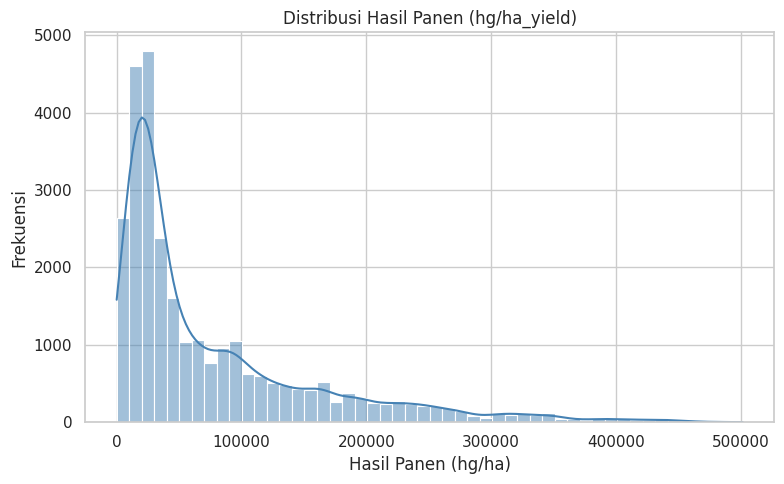

In [4]:
#@title Target Variable Distribution (hg/ha_yield)
df_main = datasets['yield_df.csv'].loc[:, ~datasets['yield_df.csv'].columns.str.contains('^Unnamed')]

plt.figure(figsize=(8, 5))
sns.histplot(df_main['hg/ha_yield'], bins=50, kde=True, color='steelblue')
plt.title('Distribusi Hasil Panen (hg/ha_yield)')
plt.xlabel('Hasil Panen (hg/ha)')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.savefig('eda_plots/eda_1_distribusi_yield.png', dpi=300)
plt.show()

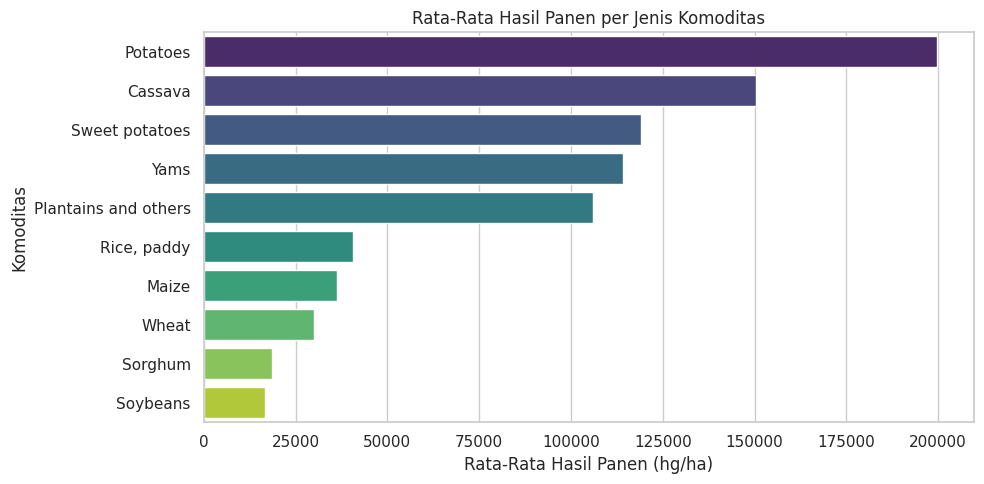

In [5]:
#@title Average Crop Yield by Commodity (Item)
plt.figure(figsize=(10, 5))
avg_yield_crop = df_main.groupby('Item')['hg/ha_yield'].mean().sort_values(ascending=False)
sns.barplot(
    x=avg_yield_crop.values,
    y=avg_yield_crop.index,
    palette='viridis',
    hue=avg_yield_crop.index,
    legend=False
)
plt.title('Rata-Rata Hasil Panen per Jenis Komoditas')
plt.xlabel('Rata-Rata Hasil Panen (hg/ha)')
plt.ylabel('Komoditas')
plt.tight_layout()
plt.savefig('eda_plots/eda_2_yield_per_komoditas.png', dpi=300)
plt.show()

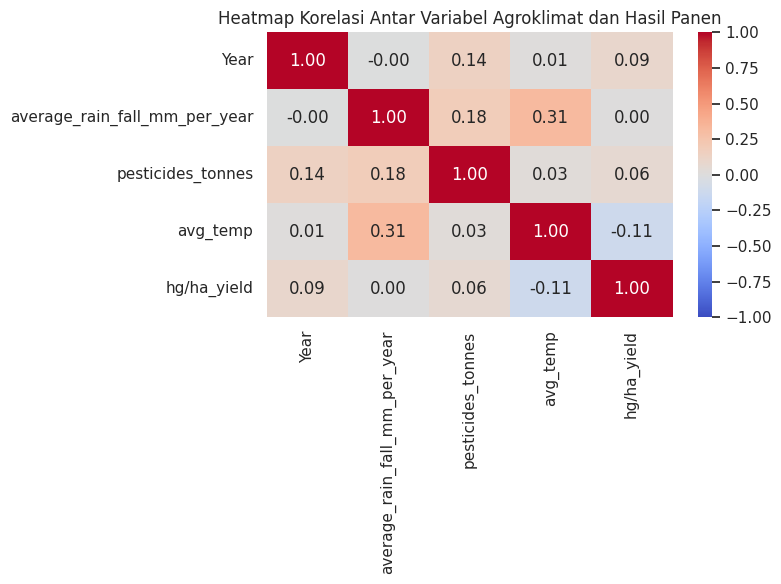

In [6]:
#@title Agrometeorological Feature Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_cols = ['Year', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'hg/ha_yield']
corr_matrix = df_main[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Antar Variabel Agroklimat dan Hasil Panen')
plt.tight_layout()
plt.savefig('eda_plots/eda_3_korelasi_fitur.png', dpi=300)
plt.show()

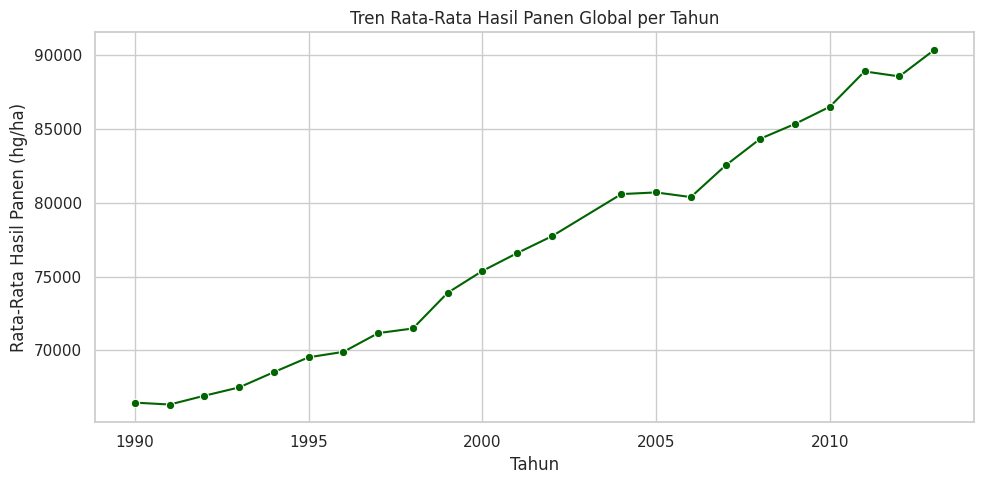

In [7]:
#@title Historical Crop Yield Trend Across Years
plt.figure(figsize=(10, 5))
yearly_trend = df_main.groupby('Year')['hg/ha_yield'].mean()
sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker='o', color='darkgreen')
plt.title('Tren Rata-Rata Hasil Panen Global per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Rata-Rata Hasil Panen (hg/ha)')
plt.tight_layout()
plt.savefig('eda_plots/eda_4_tren_tahunan.png', dpi=300)
plt.show()